# CNN

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

from PIL import ImageFile

ImageFile.LOAD_TRUNCATED_IMAGES = True

In [2]:
EPOCHS = 10
BATCH_SIZE = 32
LR = 0.001
IMG_SIZE = 224

import random

random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

ROOT = "../.."
DATA_CSV_LOC = os.path.join(ROOT, "DATA_PP")

device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "mps" if torch.backends.mps.is_available()
    else "cpu"
)

print(device)

mps


In [3]:
train_df = pd.read_csv(DATA_CSV_LOC + "/train.csv")
val_df = pd.read_csv(DATA_CSV_LOC + "/val.csv")
test_df = pd.read_csv(DATA_CSV_LOC + "/test.csv")

classes = sorted(train_df["label"].unique())
class_to_idx = {c: i for i, c in enumerate(classes)}

print(class_to_idx)
print(len(train_df), len(val_df), len(test_df))

{'ABE': 0, 'BLA': 1, 'FGC': 2, 'HAC': 3, 'KSC': 4, 'LYI': 5, 'normal': 6}
103538 22187 22187


In [4]:
"""import os
import shutil

source_dir = "../../DATA/bone_marrow_cell_dataset"
output_dir = "../../DATA_PP"

abnormal = {"ABE", "BLA", "FGC", "HAC", "KSC", "LYI"}
exclude = {"ART", "NIF", "OTH"}

copied = 0

for category in os.listdir(source_dir):
    if category in exclude:
        continue

    label = category if category in abnormal else "normal"
    src_folder = os.path.join(source_dir, category)
    dst_folder = os.path.join(output_dir, label)

    os.makedirs(dst_folder, exist_ok=True)

    for root, dirs, files in os.walk(src_folder):
        for filename in files:
            src = os.path.join(root, filename)
            dst = os.path.join(dst_folder, filename)

            if os.path.exists(dst):
                continue

            shutil.copy2(src, dst)
            copied += 1

print("New images copied:", copied) """

'import os\nimport shutil\n\nsource_dir = "../../DATA/bone_marrow_cell_dataset"\noutput_dir = "../../DATA_PP"\n\nabnormal = {"ABE", "BLA", "FGC", "HAC", "KSC", "LYI"}\nexclude = {"ART", "NIF", "OTH"}\n\ncopied = 0\n\nfor category in os.listdir(source_dir):\n    if category in exclude:\n        continue\n\n    label = category if category in abnormal else "normal"\n    src_folder = os.path.join(source_dir, category)\n    dst_folder = os.path.join(output_dir, label)\n\n    os.makedirs(dst_folder, exist_ok=True)\n\n    for root, dirs, files in os.walk(src_folder):\n        for filename in files:\n            src = os.path.join(root, filename)\n            dst = os.path.join(dst_folder, filename)\n\n            if os.path.exists(dst):\n                continue\n\n            shutil.copy2(src, dst)\n            copied += 1\n\nprint("New images copied:", copied) '

In [5]:
for name, df in [("Train", train_df), ("Validation", val_df), ("Test", test_df)]:
    missing = 0

    for filepath in df["filepath"]:
        full_path = os.path.join(ROOT, filepath)

        if not os.path.isfile(full_path):
            missing += 1

    print(name, "- Missing images:", missing)

Train - Missing images: 0
Validation - Missing images: 0
Test - Missing images: 0


In [6]:
class BoneMarrowDataset(Dataset):
    def __init__(self, df, root, transform=None):
        self.df = df.reset_index(drop=True)
        self.root = root
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        image_path = os.path.join(self.root, row["filepath"])
        image = Image.open(image_path).convert("RGB")

        label = class_to_idx[row["label"]]

        if self.transform:
            image = self.transform(image)

        return image, label

In [7]:
train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor()
])

val_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor()
])

In [8]:
train_dataset = BoneMarrowDataset(train_df, ROOT, train_transform)
val_dataset = BoneMarrowDataset(val_df, ROOT, val_transform)
test_dataset = BoneMarrowDataset(test_df, ROOT, val_transform)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

print(len(train_dataset), len(val_dataset), len(test_dataset))


103538 22187 22187


In [9]:
class BoneMarrowCNN(nn.Module):
    def __init__(self, num_classes=7, dropout=0.3):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d((1, 1)),
            nn.Flatten(),
            nn.Dropout(dropout),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

In [10]:
class_counts = train_df["label"].value_counts()

weights = []

for c in classes:
    weight = (len(train_df) / (len(classes) * class_counts[c])) ** 0.5
    weights.append(weight)

class_weights = torch.tensor(
    weights, dtype=torch.float32
).to(device)

print("Updated class weights:")
for c, w in zip(classes, weights):
    print(c, round(w, 4))

Updated class weights:
ABE 49.6507
BLA 1.3285
FGC 21.1711
HAC 7.1915
KSC 22.2045
LYI 18.1299
normal 0.3951


In [11]:
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()

    total_loss = 0
    correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        total_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    avg_loss = total_loss / total
    accuracy = correct / total

    return avg_loss, accuracy

In [12]:
def validate(model, loader, criterion, device):
    model.eval()

    total_loss = 0
    correct = 0
    total = 0
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            total_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)
            correct += (predictions == labels).sum().item()
            total += labels.size(0)

            all_preds.extend(predictions.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    avg_loss = total_loss / total
    accuracy = correct / total
    macro_f1 = f1_score(
        all_labels,
        all_preds,
        labels=list(range(len(classes))),
        average="macro",
        zero_division=0
    )

    return avg_loss, accuracy, macro_f1


In [13]:
model = BoneMarrowCNN(num_classes=7).to(device)
criterion = nn.CrossEntropyLoss(weight=class_weights)
optimizer = torch.optim.Adam(model.parameters(), lr=LR)

In [14]:
train_losses = []
val_losses = []
train_accuracies = []
val_accuracies = []
val_f1_scores = []

best_f1 = -1

for epoch in range(EPOCHS):
    train_loss, train_acc = train_one_epoch(
        model, train_loader, criterion, optimizer, device
    )

    val_loss, val_acc, val_f1 = validate(
        model, val_loader, criterion, device
    )

    train_losses.append(train_loss)
    val_losses.append(val_loss)
    train_accuracies.append(train_acc)
    val_accuracies.append(val_acc)
    val_f1_scores.append(val_f1)

    print(f"Epoch {epoch + 1}/{EPOCHS}")
    print(f"Train Loss: {train_loss:.4f} | Train Accuracy: {train_acc:.4f}")
    print(f"Val Loss: {val_loss:.4f} | Val Accuracy: {val_acc:.4f} | Macro F1: {val_f1:.4f}")

    if val_f1 > best_f1:
        best_f1 = val_f1
        torch.save(model.state_dict(), "best_cnn.pth")
        print("Saved best model!")

    print()


Epoch 1/10
Train Loss: 0.7619 | Train Accuracy: 0.9114
Val Loss: 0.7110 | Val Accuracy: 0.8835 | Macro F1: 0.1517
Saved best model!

Epoch 2/10
Train Loss: 0.7065 | Train Accuracy: 0.9040
Val Loss: 0.6438 | Val Accuracy: 0.9095 | Macro F1: 0.1544
Saved best model!

Epoch 3/10
Train Loss: 0.6616 | Train Accuracy: 0.8966
Val Loss: 0.5801 | Val Accuracy: 0.9092 | Macro F1: 0.1905
Saved best model!

Epoch 4/10
Train Loss: 0.6038 | Train Accuracy: 0.9006
Val Loss: 0.5448 | Val Accuracy: 0.8989 | Macro F1: 0.2055
Saved best model!

Epoch 5/10
Train Loss: 0.5838 | Train Accuracy: 0.9024
Val Loss: 0.5275 | Val Accuracy: 0.9210 | Macro F1: 0.2433
Saved best model!

Epoch 6/10
Train Loss: 0.5666 | Train Accuracy: 0.9025
Val Loss: 0.5271 | Val Accuracy: 0.9187 | Macro F1: 0.2059

Epoch 7/10
Train Loss: 0.5573 | Train Accuracy: 0.9036
Val Loss: 0.5396 | Val Accuracy: 0.9084 | Macro F1: 0.2414

Epoch 8/10
Train Loss: 0.5433 | Train Accuracy: 0.9055
Val Loss: 0.5008 | Val Accuracy: 0.9165 | Macro F1

In [15]:
model.load_state_dict(
    torch.load("best_cnn.pth", map_location=device, weights_only=True)
)

model.eval()

all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        all_preds.extend(predictions.cpu().numpy())
        all_labels.extend(labels.numpy())

print(classification_report(
    all_labels,
    all_preds,
    labels=list(range(len(classes))),
    target_names=classes,
    zero_division=0
))

              precision    recall  f1-score   support

         ABE       0.00      0.00      0.00         1
         BLA       0.60      0.35      0.45      1796
         FGC       0.14      0.14      0.14         7
         HAC       0.00      0.00      0.00        62
         KSC       0.50      0.50      0.50         6
         LYI       0.00      0.00      0.00        10
      normal       0.94      0.98      0.96     20305

    accuracy                           0.93     22187
   macro avg       0.31      0.28      0.29     22187
weighted avg       0.91      0.93      0.91     22187



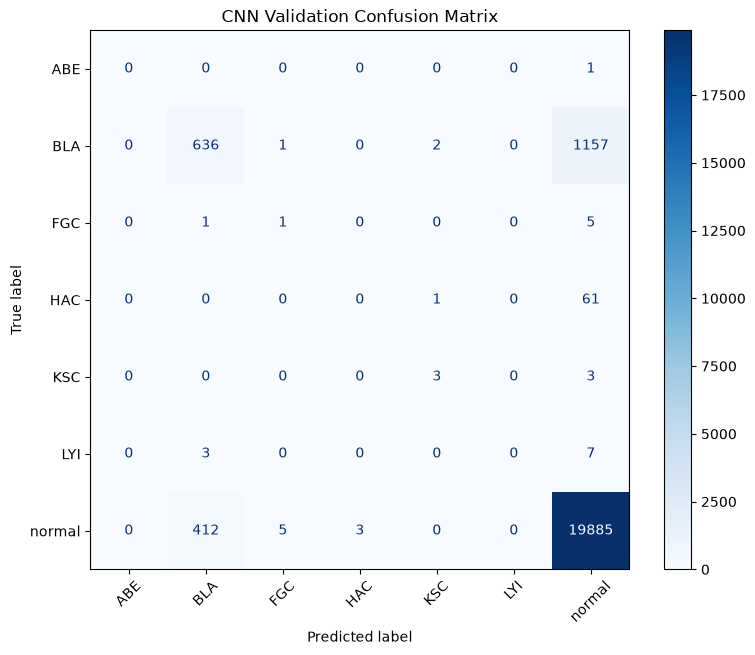

In [16]:
from sklearn.metrics import ConfusionMatrixDisplay

cm = confusion_matrix(
    all_labels,
    all_preds,
    labels=list(range(len(classes)))
)

fig, ax = plt.subplots(figsize=(9, 7))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=classes
)

disp.plot(ax=ax, cmap="Blues", values_format="d")
plt.title("CNN Validation Confusion Matrix")
plt.xticks(rotation=45)
plt.show()